<a href="https://colab.research.google.com/github/HoussamEddineBoukhalfa/dropout-medmnist/blob/Task-D/mc_dropout_taskD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
!pip install -q medmnist

import random, time, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from medmnist import PathMNIST
import hashlib


device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "| torch", torch.__version__)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

DATA_SEED = 0          # common seed for ALL groups: fixes the 4,500 subset and the val/test split
TRAIN_SEEDS = [0, 1, 2]  # 3 seeds for the final evaluation
N_CLASSES = 9

Device: cuda | torch 2.11.0+cu130


In [34]:
tr = PathMNIST(split="train", download=True)
va = PathMNIST(split="val",   download=True)
te = PathMNIST(split="test",  download=True)   # official test = OTHER center

X_tr, y_tr = tr.imgs, tr.labels.squeeze()
X_va, y_va = va.imgs, va.labels.squeeze()
X_te, y_te = te.imgs, te.labels.squeeze()

print(X_tr.shape, X_va.shape, X_te.shape)   # expect (90000,28,28,3), (10000,...), (7180,...)
print("train class counts:", np.bincount(y_tr))

(89996, 28, 28, 3) (10004, 28, 28, 3) (7180, 28, 28, 3)
train class counts: [ 9366  9509 10360 10401  8006 12182  7886  9401 12885]


In [35]:
rng = np.random.RandomState(DATA_SEED)

# 2,000 images of the official val -> "same-center" test (used ONCE at the end)
perm = rng.permutation(len(X_va))
idx_same, idx_val = perm[:2000], perm[2000:]          # 2,000 / 8,000

# balanced subset: 500 images per class = 4,500 (5 %)
per_class = 4500 // N_CLASSES
idx_sub = np.concatenate([
    rng.choice(np.where(y_tr == c)[0], per_class, replace=False)
    for c in range(N_CLASSES)
])
rng.shuffle(idx_sub)

Xtr_np, ytr_np = X_tr[idx_sub], y_tr[idx_sub]
Xval_np, yval_np = X_va[idx_val], y_va[idx_val]
Xsame_np, ysame_np = X_va[idx_same], y_va[idx_same]

print("train:", Xtr_np.shape, np.bincount(ytr_np))
print("val:", Xval_np.shape, "| same-center test:", Xsame_np.shape, "| other-center test:", X_te.shape)

train: (4500, 28, 28, 3) [500 500 500 500 500 500 500 500 500]
val: (8004, 28, 28, 3) | same-center test: (2000, 28, 28, 3) | other-center test: (7180, 28, 28, 3)


In [36]:
# mean/std computed on the 4,500 TRAINING images only (no leakage from val/test)
mean = Xtr_np.reshape(-1, 3).mean(0) / 255.0
std  = Xtr_np.reshape(-1, 3).std(0)  / 255.0
print("mean", mean, "std", std)

def to_tensor(X, y):
    X = torch.from_numpy(X).float().div(255.0).permute(0, 3, 1, 2)   # N,3,28,28
    X = (X - torch.tensor(mean).view(1, 3, 1, 1).float()) / torch.tensor(std).view(1, 3, 1, 1).float()
    return X.to(device), torch.from_numpy(y).long().to(device)

Xtr, ytr       = to_tensor(Xtr_np, ytr_np)
Xval, yval     = to_tensor(Xval_np, yval_np)
Xsame, ysame   = to_tensor(Xsame_np, ysame_np)
Xother, yother = to_tensor(X_te, y_te)

# sanity checks: the subsets must not overlap
assert len(idx_sub) == 4500 and len(set(idx_same) & set(idx_val)) == 0

mean [0.74202645 0.53959818 0.70906785] std [0.1245968  0.17957581 0.12619891]


In [37]:
class BaseCNN(nn.Module):
    def __init__(self, n_classes=9, dropout=0.0):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.fc1 = nn.Linear(128 * 3 * 3, 256)   # 28 -> 14 -> 7 -> 3
        self.drop = nn.Dropout(dropout)          # 0.0 = no dropout in the baseline
        self.out = nn.Linear(256, n_classes)

    def forward(self, x):
        x = self.features(x).flatten(1)
        x = self.drop(F.relu(self.fc1(x)))
        return self.out(x)

m = BaseCNN(N_CLASSES)
print("Parameters:", sum(p.numel() for p in m.parameters()))   # expect 584,489
print(m(Xtr[:4].cpu()).shape)                                    # expect (4, 9)

Parameters: 584489
torch.Size([4, 9])


In [ ]:
@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval()
    logits = torch.cat([model(X[i:i+bs]) for i in range(0, len(X), bs)])
    loss = F.cross_entropy(logits, y).item()
    acc = (logits.argmax(1) == y).float().mean().item()
    return loss, acc, logits

def he_init(m):
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
        nn.init.zeros_(m.bias)

def make():
    m = BaseCNN(N_CLASSES)
    m.apply(he_init)
    return m

CLIP = 1.0   # part of the baseline, used for ALL methods in the group

def train(model, seed, epochs=100, lr=0.05, bs=128, momentum=0.9,
          weight_decay=0.0, clip=None, verbose=True):
    set_seed(seed)
    model = model.to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum,
                          weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    n = len(Xtr)

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, bs):
            idx = perm[i:i+bs]
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            if clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
        sched.step()

        # per-epoch monitoring (train and val only, never the test sets)
        tl, ta, _ = evaluate(model, Xtr, ytr)
        vl, va_, _ = evaluate(model, Xval, yval)
        for k, v in zip(hist, [tl, ta, vl, va_]):
            hist[k].append(v)
        if verbose and (ep % 10 == 0 or ep == epochs - 1):
            print(f"ep {ep:3d} | train {tl:.4f}/{ta:.3f} | val {vl:.4f}/{va_:.3f}")
        if not np.isfinite(tl):
            print("diverged at epoch", ep); break

    return model, hist   # model = LAST epoch (no early stopping)

def final_eval(model):
    """Call ONLY at the very end, once per final model."""
    _, tr_acc, _ = evaluate(model, Xtr, ytr)
    _, same_acc, _ = evaluate(model, Xsame, ysame)
    _, other_acc, _ = evaluate(model, Xother, yother)
    return {"train_acc": tr_acc, "same_acc": same_acc, "other_acc": other_acc,
            "overfit_gap": tr_acc - same_acc, "center_gap": same_acc - other_acc}

## Training instability of the baseline (NaN divergence) and fix

**Phenomenon.** With the specified recipe (SGD, lr = 0.05, momentum = 0.9, no normalisation), the unregularised CNN diverged. The loss stayed near ln(9) ≈ 2.19 (chance level) at epoch 0, then became `NaN`, and accuracy stayed at 11% (1/9, chance) for the rest of training.

**Cause.** The network has 6 convolutional layers stacked without any normalisation. With PyTorch's default initialisation and a large learning rate plus momentum, one early update can be huge. The weights then blow up, the activations overflow to `inf`, and every later step produces `NaN`.

**Fix (applied identically to the baseline and to all methods).**
1. **He (Kaiming) initialisation** of conv and linear weights, the standard init for ReLU networks.
2. **Gradient-norm clipping at 1.0**, which caps the size of a single update when the gradient is very large.

Neither change limits the model's capacity or penalises the weights, so they are not regularisers and the baseline remains unregularised.

**Stability test (seed 0, 15 epochs).**

| Setting | Result |
|---|---|
| He init, lr 0.05 | diverged at epoch 1 |
| He init + clip 1.0, lr 0.05 | stable, train 95.3% / val 76.9% |
| He init, lr 0.02 | stable but slower, train 76.0% / val 70.3% |

**Decision.** We kept **He init + clip 1.0 at lr = 0.05**, so the learning rate from the specification is unchanged. This deviation from the specified recipe is reported, and it applies to every experiment (dropout, DropBlock, MC dropout) so that comparisons stay fair.

ep   0 | train 1.4548/0.480 | val 1.4545/0.480
ep  10 | train 0.3061/0.894 | val 0.8980/0.706
ep  20 | train 0.0635/0.981 | val 1.3024/0.714
ep  30 | train 0.0287/0.992 | val 1.5995/0.714
ep  40 | train 0.0225/0.993 | val 1.9851/0.709
ep  50 | train 0.0034/0.998 | val 2.0890/0.742
ep  60 | train 0.0006/1.000 | val 2.0096/0.744
ep  70 | train 0.0000/1.000 | val 2.0532/0.748
ep  80 | train 0.0000/1.000 | val 2.0627/0.748
ep  90 | train 0.0000/1.000 | val 2.0660/0.748
ep  99 | train 0.0000/1.000 | val 2.0664/0.748
Done in 87s


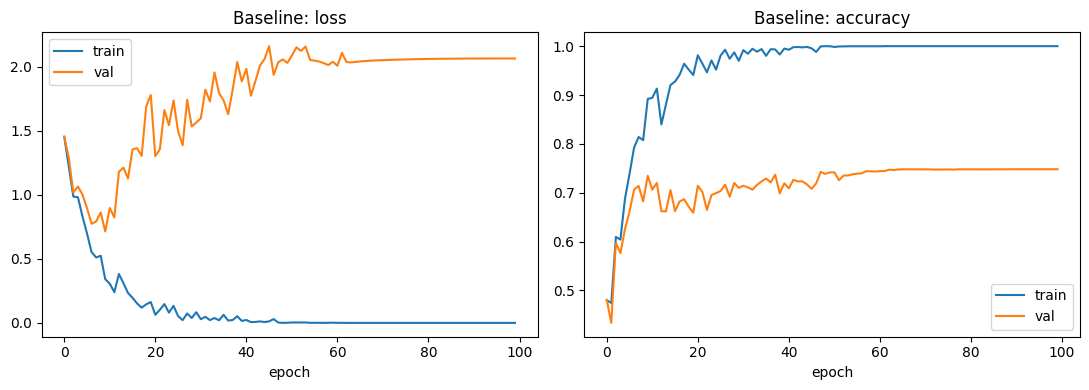

min val loss at epoch 9 | final val loss 2.0664 | final train loss 0.0 | final train acc 1.0 | final val acc 0.748


In [ ]:
import matplotlib.pyplot as plt

def plot_curves(hist, title="Baseline"):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="val")
    ax[0].set_title(f"{title}: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["train_acc"], label="train"); ax[1].plot(hist["val_acc"], label="val")
    ax[1].set_title(f"{title}: accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

t0 = time.time()
model, hist = train(make(), seed=0, clip=CLIP)      # <- changed: make() + clip=CLIP
print(f"Done in {time.time()-t0:.0f}s")

plot_curves(hist)
print("min val loss at epoch", int(np.argmin(hist["val_loss"])),
      "| final val loss", round(hist["val_loss"][-1], 4),
      "| final train loss", round(hist["train_loss"][-1], 4),
      "| final train acc", round(hist["train_acc"][-1], 3),
      "| final val acc", round(hist["val_acc"][-1], 3))

In [ ]:
baseline_runs = []
for s in TRAIN_SEEDS:
    t0 = time.time()
    m, h = train(make(), seed=s, clip=CLIP, verbose=False)
    r = final_eval(m)                      # first and only use of the test sets for this model
    r["seed"] = s
    r["final_val_loss"] = h["val_loss"][-1]
    r["final_val_acc"] = h["val_acc"][-1]
    r["min_val_loss"] = float(np.min(h["val_loss"]))
    r["epoch_min_val_loss"] = int(np.argmin(h["val_loss"]))
    baseline_runs.append(r)
    print(f"seed {s} ({time.time()-t0:.0f}s) |",
          {k: round(v, 4) for k, v in r.items() if k != "seed"})

def summarize(runs):
    keys = ["train_acc", "same_acc", "other_acc", "overfit_gap", "center_gap"]
    return {k: (float(np.mean([r[k] for r in runs])), float(np.std([r[k] for r in runs])))
            for k in keys}

baseline_summary = summarize(baseline_runs)
print("\nBaseline, mean ± std over 3 seeds")
for k, (mu, sd) in baseline_summary.items():
    print(f"{k:12s}: {mu:.4f} ± {sd:.4f}")

seed 0 (88s) | {'train_acc': 1.0, 'same_acc': 0.7595, 'other_acc': 0.7591, 'overfit_gap': 0.2405, 'center_gap': 0.0004, 'final_val_loss': 2.1343, 'final_val_acc': 0.7499, 'min_val_loss': 0.7552, 'epoch_min_val_loss': 6}
seed 1 (88s) | {'train_acc': 1.0, 'same_acc': 0.761, 'other_acc': 0.7359, 'overfit_gap': 0.239, 'center_gap': 0.0251, 'final_val_loss': 1.8791, 'final_val_acc': 0.7676, 'min_val_loss': 0.7034, 'epoch_min_val_loss': 7}
seed 2 (88s) | {'train_acc': 1.0, 'same_acc': 0.746, 'other_acc': 0.7549, 'overfit_gap': 0.254, 'center_gap': -0.0089, 'final_val_loss': 1.9855, 'final_val_acc': 0.758, 'min_val_loss': 0.8017, 'epoch_min_val_loss': 12}

Baseline, mean ± std over 3 seeds
train_acc   : 1.0000 ± 0.0000
same_acc    : 0.7555 ± 0.0067
other_acc   : 0.7500 ± 0.0101
overfit_gap : 0.2445 ± 0.0067
center_gap  : 0.0055 ± 0.0143


In [ ]:
def make_dropout(p):
    """Standard dropout on the dense layer (256 neurons), He init as in the baseline."""
    m = BaseCNN(N_CLASSES, dropout=p)
    m.apply(he_init)
    return m

def sweep(constructor, grid, seed=0):
    """1 seed, validation only. The test sets are never touched here."""
    rows, hists = [], {}
    for v in grid:
        t0 = time.time()
        _, h = train(constructor(v), seed=seed, clip=CLIP, verbose=False)
        row = {"value": v,
               "val_acc": h["val_acc"][-1],      # last epoch (no early stopping)
               "val_loss": h["val_loss"][-1],
               "train_acc": h["train_acc"][-1]}
        rows.append(row); hists[v] = h
        print(f"{v:<5} ({time.time()-t0:.0f}s) | val acc {row['val_acc']:.4f} | "
              f"val loss {row['val_loss']:.4f} | train acc {row['train_acc']:.3f}")
    return rows, hists

DROPOUT_GRID = [0.3, 0.5, 0.6, 0.7, 0.8]
sweep_rows, sweep_hists = sweep(make_dropout, DROPOUT_GRID, seed=0)

# selection rule (fixed in advance): highest last-epoch val accuracy, ties -> lower val loss
best = max(sweep_rows, key=lambda r: (round(r["val_acc"], 4), -r["val_loss"]))
BEST_P = best["value"]
print("\nSelected dropout rate:", BEST_P)

0.3   (88s) | val acc 0.8153 | val loss 1.3576 | train acc 1.000
0.5   (88s) | val acc 0.8423 | val loss 1.1633 | train acc 1.000
0.6   (88s) | val acc 0.8465 | val loss 1.0468 | train acc 1.000
0.7   (87s) | val acc 0.8648 | val loss 1.0338 | train acc 1.000
0.8   (87s) | val acc 0.8758 | val loss 0.9865 | train acc 1.000

Selected dropout rate: 0.8


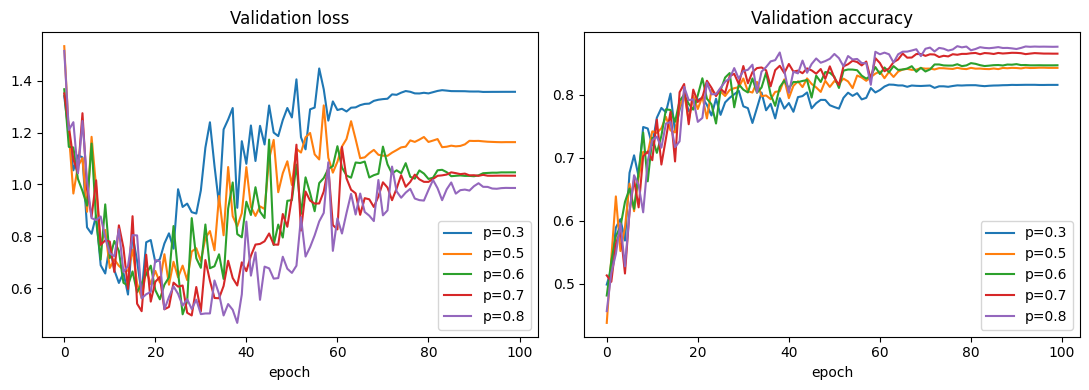

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for v, h in sweep_hists.items():
    ax[0].plot(h["val_loss"], label=f"p={v}")
    ax[1].plot(h["val_acc"], label=f"p={v}")
ax[0].set_title("Validation loss"); ax[1].set_title("Validation accuracy")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
print("Dropout rate used:", BEST_P)

dropout_runs, dropout_hists = [], []
for s in TRAIN_SEEDS:
    t0 = time.time()
    m, h = train(make_dropout(BEST_P), seed=s, clip=CLIP, verbose=False)
    r = final_eval(m)                      # first and only use of the test sets for this model
    r["seed"] = s
    r["final_val_loss"] = h["val_loss"][-1]
    r["final_val_acc"] = h["val_acc"][-1]
    dropout_runs.append(r); dropout_hists.append(h)
    print(f"seed {s} ({time.time()-t0:.0f}s) |",
          {k: round(v, 4) for k, v in r.items() if k != "seed"})

dropout_summary = summarize(dropout_runs)

print(f"\n{'metric':12s} {'baseline':>16s} {'dropout':>16s} {'difference':>10s}")
for k in baseline_summary:
    b_mu, b_sd = baseline_summary[k]
    d_mu, d_sd = dropout_summary[k]
    print(f"{k:12s} {b_mu:.4f} ± {b_sd:.4f}   {d_mu:.4f} ± {d_sd:.4f}   {d_mu-b_mu:+.4f}")

Dropout rate used: 0.8
seed 0 (88s) | {'train_acc': 1.0, 'same_acc': 0.8735, 'other_acc': 0.832, 'overfit_gap': 0.1265, 'center_gap': 0.0415, 'final_val_loss': 1.0029, 'final_val_acc': 0.8803}
seed 1 (88s) | {'train_acc': 1.0, 'same_acc': 0.865, 'other_acc': 0.8326, 'overfit_gap': 0.135, 'center_gap': 0.0324, 'final_val_loss': 0.9772, 'final_val_acc': 0.8764}
seed 2 (88s) | {'train_acc': 1.0, 'same_acc': 0.864, 'other_acc': 0.8231, 'overfit_gap': 0.136, 'center_gap': 0.0409, 'final_val_loss': 1.0955, 'final_val_acc': 0.8692}

metric               baseline          dropout difference
train_acc    1.0000 ± 0.0000   1.0000 ± 0.0000   +0.0000
same_acc     0.7555 ± 0.0067   0.8675 ± 0.0043   +0.1120
other_acc    0.7500 ± 0.0101   0.8292 ± 0.0043   +0.0793
overfit_gap  0.2445 ± 0.0067   0.1325 ± 0.0043   -0.1120
center_gap   0.0055 ± 0.0143   0.0383 ± 0.0041   +0.0327


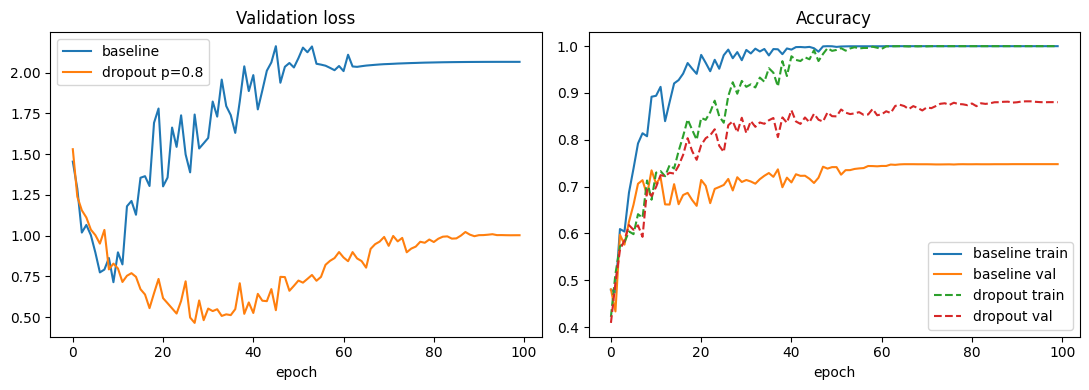

In [ ]:
# `hist` is the baseline seed-0 history from cell 7
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["val_loss"], label="baseline")
ax[0].plot(dropout_hists[0]["val_loss"], label=f"dropout p={BEST_P}")
ax[0].set_title("Validation loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(hist["train_acc"], label="baseline train")
ax[1].plot(hist["val_acc"], label="baseline val")
ax[1].plot(dropout_hists[0]["train_acc"], "--", label="dropout train")
ax[1].plot(dropout_hists[0]["val_acc"], "--", label="dropout val")
ax[1].set_title("Accuracy"); ax[1].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

**DermaMNIST**

In [ ]:
from medmnist import DermaMNIST
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

# Back up PathMNIST tensors: the next lines overwrite the global names used by train()/evaluate()
PATH = dict(Xtr=Xtr, ytr=ytr, Xval=Xval, yval=yval, Xsame=Xsame, ysame=ysame,
            Xother=Xother, yother=yother, mean=mean, std=std, N_CLASSES=N_CLASSES)

dtr = DermaMNIST(split="train", download=True)
dva = DermaMNIST(split="val",   download=True)
dte = DermaMNIST(split="test",  download=True)

# normalisation statistics from the DermaMNIST TRAIN set only
mean = dtr.imgs.reshape(-1, 3).mean(0) / 255.0
std  = dtr.imgs.reshape(-1, 3).std(0)  / 255.0
N_CLASSES = 7

Xtr,  ytr  = to_tensor(dtr.imgs, dtr.labels.squeeze())
Xval, yval = to_tensor(dva.imgs, dva.labels.squeeze())
Xte,  yte  = to_tensor(dte.imgs, dte.labels.squeeze())

print("train", Xtr.shape, "val", Xval.shape, "test", Xte.shape)
print("train class counts:", np.bincount(ytr.cpu().numpy()))

100%|██████████| 19.7M/19.7M [00:25<00:00, 786kB/s]


train torch.Size([7007, 3, 28, 28]) val torch.Size([1003, 3, 28, 28]) test torch.Size([2005, 3, 28, 28])
train class counts: [ 228  359  769   80  779 4693   99]


In [ ]:
def derma_eval(model, X, y):
    _, acc, logits = evaluate(model, X, y)
    p = F.softmax(logits.double(), 1).cpu().numpy()
    p /= p.sum(1, keepdims=True)
    yt = y.cpu().numpy()
    return {"acc": acc,
            "bal_acc": balanced_accuracy_score(yt, p.argmax(1)),
            "auc": roc_auc_score(yt, p, multi_class="ovr", average="macro")}

def derma_sweep(constructor, grid, seed=0):
    """1 seed, validation only. Rule: highest last-epoch val balanced accuracy."""
    rows = []
    for v in grid:
        t0 = time.time()
        m, h = train(constructor(v), seed=seed, clip=CLIP, verbose=False)
        r = derma_eval(m, Xval, yval); r["value"] = v
        rows.append(r)
        print(f"{v:<5} ({time.time()-t0:.0f}s) | val acc {r['acc']:.4f} | "
              f"val bal_acc {r['bal_acc']:.4f} | val auc {r['auc']:.4f}")
    return rows, max(rows, key=lambda r: r["bal_acc"])["value"]

def derma_final(constructor, seeds=TRAIN_SEEDS):
    """3 seeds. Test set used once per final model."""
    runs = []
    for s in seeds:
        m, h = train(constructor(), seed=s, clip=CLIP, verbose=False)
        r = {f"{split}_{k}": v
             for split, (X, y) in {"train": (Xtr, ytr), "test": (Xte, yte)}.items()
             for k, v in derma_eval(m, X, y).items()}
        r["seed"] = s; runs.append(r)
        print(s, {k: round(v, 4) for k, v in r.items() if k != "seed"})
    return runs

def derma_summary(runs):
    keys = [k for k in runs[0] if k != "seed"]
    return {k: (float(np.mean([r[k] for r in runs])), float(np.std([r[k] for r in runs]))) for k in keys}

In [ ]:
d_base_runs = derma_final(make)
d_base = derma_summary(d_base_runs)

0 {'train_acc': 1.0, 'train_bal_acc': np.float64(1.0), 'train_auc': np.float64(1.0), 'test_acc': 0.7372, 'test_bal_acc': np.float64(0.4574), 'test_auc': np.float64(0.8998)}
1 {'train_acc': 1.0, 'train_bal_acc': np.float64(1.0), 'train_auc': np.float64(1.0), 'test_acc': 0.7342, 'test_bal_acc': np.float64(0.476), 'test_auc': np.float64(0.8956)}
2 {'train_acc': 1.0, 'train_bal_acc': np.float64(1.0), 'train_auc': np.float64(1.0), 'test_acc': 0.7511, 'test_bal_acc': np.float64(0.4853), 'test_auc': np.float64(0.9042)}


In [ ]:
d_rows, D_BEST_P = derma_sweep(make_dropout, DROPOUT_GRID, seed=0)
print("Selected dropout rate (DermaMNIST):", D_BEST_P)

0.3   (99s) | val acc 0.7607 | val bal_acc 0.4870 | val auc 0.9120
0.5   (99s) | val acc 0.7517 | val bal_acc 0.5101 | val auc 0.9058
0.6   (99s) | val acc 0.7498 | val bal_acc 0.4437 | val auc 0.9034
0.7   (99s) | val acc 0.7567 | val bal_acc 0.4846 | val auc 0.9067
0.8   (99s) | val acc 0.7388 | val bal_acc 0.4770 | val auc 0.8998
Selected dropout rate (DermaMNIST): 0.5


In [ ]:
d_drop_runs = derma_final(lambda: make_dropout(D_BEST_P))
d_drop = derma_summary(d_drop_runs)

print(f"\n{'metric':14s} {'baseline':>16s} {'dropout':>16s} {'diff':>8s}")
for k in ["train_acc", "test_acc", "test_bal_acc", "test_auc"]:
    b, d = d_base[k], d_drop[k]
    print(f"{k:14s} {b[0]:.4f} ± {b[1]:.4f}   {d[0]:.4f} ± {d[1]:.4f}   {d[0]-b[0]:+.4f}")

0 {'train_acc': 1.0, 'train_bal_acc': np.float64(1.0), 'train_auc': np.float64(1.0), 'test_acc': 0.7377, 'test_bal_acc': np.float64(0.4855), 'test_auc': np.float64(0.9107)}
1 {'train_acc': 1.0, 'train_bal_acc': np.float64(1.0), 'train_auc': np.float64(1.0), 'test_acc': 0.7561, 'test_bal_acc': np.float64(0.4908), 'test_auc': np.float64(0.9107)}
2 {'train_acc': 1.0, 'train_bal_acc': np.float64(1.0), 'train_auc': np.float64(1.0), 'test_acc': 0.7377, 'test_bal_acc': np.float64(0.4921), 'test_auc': np.float64(0.9052)}

metric                 baseline          dropout     diff
train_acc      1.0000 ± 0.0000   1.0000 ± 0.0000   +0.0000
test_acc       0.7408 ± 0.0074   0.7438 ± 0.0087   +0.0030
test_bal_acc   0.4729 ± 0.0116   0.4895 ± 0.0028   +0.0166
test_auc       0.8999 ± 0.0035   0.9089 ± 0.0026   +0.0090


---
# Partie D : script d'évaluation commun et MC dropout
*Zineb Ben Jemaa*

Les cellules au-dessus (0 à 18) sont celles de la partie A, non modifiées.
À la reprise : lancer les cellules 0 à 5, puis directement les cellules ci-dessous.

In [38]:
def make_dropout(p):
    m = BaseCNN(N_CLASSES, dropout=p)
    m.apply(he_init)
    return m

BEST_P = 0.8

In [39]:
# ===== sauvegarde des modèles sur Google Drive =====
import os
from google.colab import drive
drive.mount("/content/drive")
SAVE_DIR = "/content/drive/MyDrive/projet_dropout/models"
os.makedirs(SAVE_DIR, exist_ok=True)
print("Les modèles seront sauvegardés dans", SAVE_DIR)




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Les modèles seront sauvegardés dans /content/drive/MyDrive/projet_dropout/models


In [40]:
# ===== CELLULE E2 : les métriques =====
from sklearn.metrics import roc_auc_score

@torch.no_grad()
def predict_probs(model, X, bs=1000):
    """Probabilités softmax (dropout ÉTEINT, prédiction classique)."""
    model.eval()
    logits = torch.cat([model(X[i:i+bs]) for i in range(0, len(X), bs)])
    return F.softmax(logits.double(), dim=1).cpu().numpy()

def ece_score(probs, y, n_bins=15):
    """Expected Calibration Error : écart moyen entre confiance et exactitude.
    0 = parfaitement calibré."""
    conf = probs.max(1)                    # confiance = proba de la classe prédite
    correct = (probs.argmax(1) == y)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        in_bin = (conf > lo) & (conf <= hi)
        if in_bin.any():
            ece += in_bin.mean() * abs(correct[in_bin].mean() - conf[in_bin].mean())
    return float(ece)

def metrics_from_probs(probs, y):
    """Exactitude, ECE et AUC à partir des probabilités (sert aussi pour le MC dropout)."""
    probs = probs / probs.sum(1, keepdims=True)
    return {"acc": float((probs.argmax(1) == y).mean()),
            "ece": ece_score(probs, y),
            "auc": float(roc_auc_score(y, probs, multi_class="ovr", average="macro"))}

def full_eval(model):
    """Évaluation finale commune : à appeler UNE fois par modèle final."""
    ytr_np_  = ytr.cpu().numpy()
    ysame_np = ysame.cpu().numpy()
    yother_np = yother.cpu().numpy()
    tr    = metrics_from_probs(predict_probs(model, Xtr), ytr_np_)
    same  = metrics_from_probs(predict_probs(model, Xsame), ysame_np)
    other = metrics_from_probs(predict_probs(model, Xother), yother_np)
    return {"train_acc": tr["acc"],
            "same_acc": same["acc"], "other_acc": other["acc"],
            "overfit_gap": tr["acc"] - same["acc"],
            "center_gap": same["acc"] - other["acc"],
            "same_ece": same["ece"], "other_ece": other["ece"],
            "same_auc": same["auc"], "other_auc": other["auc"]}




In [41]:
# ===== CELLULE E3 : entraîner (ou recharger) une méthode sur 3 graines =====
def run_method(name, constructor, seeds=TRAIN_SEEDS):
    """Entraîne `constructor()` avec chaque graine, sauvegarde le modèle sur Drive,
    puis l'évalue. Si le modèle existe déjà sur Drive, il est rechargé (pas de réentraînement)."""
    runs, models = [], []
    for s in seeds:
        path = f"{SAVE_DIR}/{name}_seed{s}.pt"
        model = constructor().to(device)
        if os.path.exists(path):
            model.load_state_dict(torch.load(path, map_location=device))
            print(f"{name} graine {s} : rechargé depuis Drive")
        else:
            t0 = time.time()
            model, _ = train(model, seed=s, clip=CLIP, verbose=False)
            torch.save(model.state_dict(), path)
            print(f"{name} graine {s} : entraîné en {time.time()-t0:.0f}s et sauvegardé")
        r = full_eval(model); r["seed"] = s
        runs.append(r); models.append(model)
    return runs, models




In [42]:
# ===== CELLULE E4 : tableau récapitulatif (moyenne ± écart-type, écart à la baseline) =====
import pandas as pd

def results_table(all_runs, baseline="baseline"):
    """all_runs = {"baseline": runs, "dropout_0.8": runs, ...}"""
    keys = [k for k in all_runs[baseline][0] if k != "seed"]
    base_mean = {k: np.mean([r[k] for r in all_runs[baseline]]) for k in keys}
    rows = {}
    for name, runs in all_runs.items():
        row = {}
        for k in keys:
            vals = [r[k] for r in runs]
            mu, sd = np.mean(vals), np.std(vals)
            row[k] = f"{mu:.4f} ± {sd:.4f}"
            if name != baseline:
                row[k] += f" ({mu - base_mean[k]:+.4f})"
        rows[name] = row
    return pd.DataFrame(rows).T




In [44]:
# ===== CELLULE B1 : charger les modèles de B (évaluation standard) =====
def load_method(name, constructor, seeds=TRAIN_SEEDS):
    """Charge uniquement depuis Drive (aucun entraînement). Erreur si un fichier manque."""
    runs, models = [], []
    for s in seeds:
        model = constructor().to(device)
        model.load_state_dict(torch.load(f"{SAVE_DIR}/{name}_seed{s}.pt", map_location=device))
        r = full_eval(model); r["seed"] = s
        runs.append(r); models.append(model)
        print(f"{name} graine {s} : same_acc {r['same_acc']:.4f} | other_acc {r['other_acc']:.4f}")
    return runs, models

for name in ["dropblock_0.5", "spatial_0.5"]:
    ALL_RUNS[name], ALL_MODELS[name] = load_method(name, make)   # make() suffit en mode éval
results_table(ALL_RUNS)

dropblock_0.5 graine 0 : same_acc 0.8515 | other_acc 0.8091
dropblock_0.5 graine 1 : same_acc 0.8340 | other_acc 0.8065
dropblock_0.5 graine 2 : same_acc 0.8605 | other_acc 0.8325
spatial_0.5 graine 0 : same_acc 0.8675 | other_acc 0.8068
spatial_0.5 graine 1 : same_acc 0.8505 | other_acc 0.8021
spatial_0.5 graine 2 : same_acc 0.8460 | other_acc 0.8079


,train_acc,same_acc,other_acc,overfit_gap,center_gap,same_ece,other_ece,same_auc,other_auc
baseline,1.0000 ± 0.0000,0.7543 ± 0.0039,0.7340 ± 0.0176,0.2457 ± 0.0039,0.0204 ± 0.0157,0.2019 ± 0.0009,0.2222 ± 0.0146,0.9590 ± 0.0016,0.9440 ± 0.0106
dropout_0.8,1.0000 ± 0.0000 (+0.0000),0.8725 ± 0.0029 (+0.1182),0.8264 ± 0.0141 (+0.0924),0.1275 ± 0.0029 (-0.1182),0.0461 ± 0.0139 (+0.0258),0.1042 ± 0.0037 (-0.0977),0.1495 ± 0.0125 (-0.0726),0.9882 ± 0.0006 (+0.0292),0.9639 ± 0.0036 (+0.0199)
dropblock_0.5,1.0000 ± 0.0000 (+0.0000),0.8487 ± 0.0110 (+0.0943),0.8160 ± 0.0117 (+0.0820),0.1513 ± 0.0110 (-0.0943),0.0326 ± 0.0069 (+0.0123),0.1043 ± 0.0073 (-0.0977),0.1368 ± 0.0102 (-0.0854),0.9842 ± 0.0018 (+0.0252),0.9697 ± 0.0034 (+0.0257)
spatial_0.5,0.9926 ± 0.0047 (-0.0074),0.8547 ± 0.0093 (+0.1003),0.8056 ± 0.0025 (+0.0716),0.1379 ± 0.0053 (-0.1077),0.0490 ± 0.0092 (+0.0287),0.0821 ± 0.0069 (-0.1198),0.1277 ± 0.0051 (-0.0944),0.9861 ± 0.0015 (+0.0271),0.9618 ± 0.0044 (+0.0178)


# MC Dropout

In [45]:
# ===== Ceci est juste une copie de l'architecture de B (avec noms changés ppour éviter les conflits) =====
class DropBlock2d(nn.Module):
    """Ghiasi et al. 2018 (code de B, inchangé). Éteint des carrés de block_size x block_size."""
    def __init__(self, drop_prob, block_size=3):
        super().__init__()
        self.target, self.drop_prob, self.block_size = drop_prob, drop_prob, block_size

    def forward(self, x):
        if not self.training or self.drop_prob == 0:     # au test (eval) : ne fait rien
            return x
        _, _, h, w = x.shape
        bs = min(self.block_size, h, w)
        if bs % 2 == 0:
            bs -= 1
        gamma = self.drop_prob / bs ** 2 * (h * w) / ((h - bs + 1) * (w - bs + 1))
        seeds = torch.zeros_like(x)
        valid = (slice(None), slice(None), slice(bs // 2, h - bs // 2), slice(bs // 2, w - bs // 2))
        seeds[valid] = (torch.rand_like(seeds[valid]) < gamma).float()
        mask = 1 - F.max_pool2d(seeds, bs, stride=1, padding=bs // 2)
        return x * mask * mask.numel() / mask.sum().clamp(min=1.0)

def make_drop_B(kind, rate, block_size=3):
    if kind == "spatial":
        return nn.Dropout2d(rate)                 # éteint des cartes (canaux) entières
    if kind == "dropblock":
        return DropBlock2d(rate, block_size)      # éteint des carrés
    return nn.Identity()

class CNN_B(nn.Module):
    """CNN de B : régularisation avant le max-pool des blocs 2 et 3, rien sur la couche dense."""
    def __init__(self, kind, rate, block_size=3, drop_blocks=(2, 3)):
        super().__init__()
        blocks, c_in = [], 3
        for i, c_out in enumerate((32, 64, 128), start=1):
            layers = [nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(),
                      nn.Conv2d(c_out, c_out, 3, padding=1), nn.ReLU()]
            if i in drop_blocks:
                layers.append(make_drop_B(kind, rate, block_size))
            layers.append(nn.MaxPool2d(2))
            blocks.append(nn.Sequential(*layers))
            c_in = c_out
        self.features = nn.Sequential(*blocks)
        self.fc1 = nn.Linear(128 * 3 * 3, 256)
        self.out = nn.Linear(256, N_CLASSES)

    def forward(self, x):
        return self.out(F.relu(self.fc1(self.features(x).flatten(1))))

def make_B(kind, rate):
    m = CNN_B(kind, rate)
    m.apply(he_init)
    return m

In [46]:
# ===== prédiction Monte Carlo dropout =====
@torch.no_grad()
def mc_predict(model, X, T=50, bs=1000, seed=0):
    """Fait T passages avec le dropout ACTIF. Renvoie un tableau (T, N, 9) de probabilités."""
    model.eval()                              # tout le réseau en mode évaluation...
    for mod in model.modules():               # ...puis on parcourt toutes ses couches
        if isinstance(mod, nn.modules.dropout._DropoutNd) or isinstance(mod, DropBlock2d):
            mod.train()                       # et on rallume UNIQUEMENT le dropout
    torch.manual_seed(seed)                   # pour que les masques aléatoires soient reproductibles
    all_probs = []
    for t in range(T):                        # T passages = T "sous-réseaux" différents
        logits = torch.cat([model(X[i:i+bs]) for i in range(0, len(X), bs)])
        all_probs.append(F.softmax(logits.double(), dim=1))
    model.eval()                              # on remet le modèle dans son état normal
    return torch.stack(all_probs).cpu().numpy()   # forme (T, N, 9)

def uncertainty(P):
    """À partir des T prédictions : proba moyenne + 2 mesures d'incertitude."""
    eps = 1e-12                                            # évite log(0)
    mean = P.mean(0)                                       # (N, 9) : prédiction finale MC
    entropy = -(mean * np.log(mean + eps)).sum(1)          # entropie prédictive : incertitude TOTALE
    exp_ent = -(P * np.log(P + eps)).sum(2).mean(0)        # entropie moyenne des T passages
    mutual_info = entropy - exp_ent                        # info mutuelle : désaccord entre les passages
    return mean, entropy, mutual_info                      #   = incertitude du MODÈLE (épistémique)

In [47]:
for name, kind in [("dropblock_0.5", "dropblock"), ("spatial_0.5", "spatial")]:
    ALL_MODELS[name] = []
    for s in TRAIN_SEEDS:
        m = make_B(kind, 0.5).to(device)
        m.load_state_dict(torch.load(f"{SAVE_DIR}/{name}_seed{s}.pt", map_location=device))
        ALL_MODELS[name].append(m)

In [48]:
# ===== combien de passages T ? (validation uniquement) =====
METHODS = ["dropout_0.8", "dropblock_0.5", "spatial_0.5"]
yval_np = yval.cpu().numpy()
for name in METHODS:
    model0 = ALL_MODELS[name][0]                          # modèle graine 0
    P = mc_predict(model0, Xval, T=100, seed=0)           # 100 passages une seule fois
    print(f"\n{name} | standard :", {k: round(v, 4) for k, v in metrics_from_probs(predict_probs(model0, Xval), yval_np).items()})
    for T in [1, 5, 10, 20, 50, 100]:
        print(f"   MC T={T:<3}:", {k: round(v, 4) for k, v in metrics_from_probs(P[:T].mean(0), yval_np).items()})


dropout_0.8 | standard : {'acc': 0.8747, 'ece': 0.1037, 'auc': 0.9875}
   MC T=1  : {'acc': 0.8662, 'ece': 0.1072, 'auc': 0.9834}
   MC T=5  : {'acc': 0.8711, 'ece': 0.0801, 'auc': 0.9863}
   MC T=10 : {'acc': 0.8726, 'ece': 0.0774, 'auc': 0.9869}
   MC T=20 : {'acc': 0.8742, 'ece': 0.0738, 'auc': 0.987}
   MC T=50 : {'acc': 0.8744, 'ece': 0.0727, 'auc': 0.9874}
   MC T=100: {'acc': 0.8752, 'ece': 0.0718, 'auc': 0.9878}

dropblock_0.5 | standard : {'acc': 0.8475, 'ece': 0.1081, 'auc': 0.9843}
   MC T=1  : {'acc': 0.8257, 'ece': 0.1304, 'auc': 0.9787}
   MC T=5  : {'acc': 0.8492, 'ece': 0.0601, 'auc': 0.9838}
   MC T=10 : {'acc': 0.8518, 'ece': 0.0512, 'auc': 0.9848}
   MC T=20 : {'acc': 0.8533, 'ece': 0.0477, 'auc': 0.9852}
   MC T=50 : {'acc': 0.8544, 'ece': 0.0448, 'auc': 0.9855}
   MC T=100: {'acc': 0.8566, 'ece': 0.0424, 'auc': 0.9857}

spatial_0.5 | standard : {'acc': 0.8561, 'ece': 0.0854, 'auc': 0.9867}
   MC T=1  : {'acc': 0.8443, 'ece': 0.094, 'auc': 0.9823}
   MC T=5  : {'ac

In [49]:
# ===== dropout standard vs MC dropout (3 graines) =====
T_MC = 50
MC, rows = {}, []
for name in METHODS:
    for s, model in zip(TRAIN_SEEDS, ALL_MODELS[name]):
        for split, (X, y) in {"same": (Xsame, ysame), "other": (Xother, yother)}.items():
            y_np = y.cpu().numpy()
            p_std = predict_probs(model, X)
            p_mc, ent, mi = uncertainty(mc_predict(model, X, T=T_MC, seed=s))
            MC[(name, s, split)] = dict(y=y_np, p_std=p_std, p_mc=p_mc, ent=ent, mi=mi)
            for kind, p in [("standard", p_std), ("MC", p_mc)]:
                r = metrics_from_probs(p, y_np)
                r.update(method=name, seed=s, split=split, kind=kind)
                rows.append(r)

df_mc = pd.DataFrame(rows)
df_mc.groupby(["split", "method", "kind"])[["acc", "ece", "auc"]].agg(["mean", "std"]).round(4)

acc             ece             auc        
                                mean     std    mean     std    mean     std
split method        kind                                                    
other dropblock_0.5 MC        0.8163  0.0138  0.0677  0.0068  0.9675  0.0051
                    standard  0.8160  0.0143  0.1368  0.0125  0.9697  0.0041
      dropout_0.8   MC        0.8251  0.0170  0.1124  0.0140  0.9637  0.0051
                    standard  0.8264  0.0172  0.1495  0.0153  0.9639  0.0044
      spatial_0.5   MC        0.8271  0.0098  0.0514  0.0075  0.9669  0.0054
                    standard  0.8056  0.0031  0.1277  0.0063  0.9618  0.0054
same  dropblock_0.5 MC        0.8543  0.0091  0.0367  0.0026  0.9857  0.0016
                    standard  0.8487  0.0135  0.1043  0.0090  0.9842  0.0022
      dropout_0.8   MC        0.8735  0.0040  0.0719  0.0040  0.9880  0.0009
                    standard  0.8725  0.0036  0.1042  0.0045  0.9882  0.0007
      spatial_0.5   MC        0.8682  0.0068  0.0205  0.0009  0.9879  0.0012
                    standard  0.8547  0.0113  0.0821  0.0084  0.9861  0.0018

same  | baseline                       | 0 %: 0.7543 | 10 %: 0.7933 | 20 %: 0.8302 | gain 20 %: +0.0759
same  | dropout_0.8 | standard         | 0 %: 0.8725 | 10 %: 0.9133 | 20 %: 0.9481 | gain 20 %: +0.0756
same  | dropout_0.8 | MC entropie      | 0 %: 0.8735 | 10 %: 0.9150 | 20 %: 0.9492 | gain 20 %: +0.0757
same  | dropout_0.8 | MC info mut.     | 0 %: 0.8735 | 10 %: 0.9120 | 20 %: 0.9479 | gain 20 %: +0.0744
same  | dropblock_0.5 | standard       | 0 %: 0.8487 | 10 %: 0.8891 | 20 %: 0.9256 | gain 20 %: +0.0770
same  | dropblock_0.5 | MC entropie    | 0 %: 0.8543 | 10 %: 0.8939 | 20 %: 0.9304 | gain 20 %: +0.0761
same  | dropblock_0.5 | MC info mut.   | 0 %: 0.8543 | 10 %: 0.8919 | 20 %: 0.9298 | gain 20 %: +0.0755
same  | spatial_0.5 | standard         | 0 %: 0.8547 | 10 %: 0.8983 | 20 %: 0.9294 | gain 20 %: +0.0747
same  | spatial_0.5 | MC entropie      | 0 %: 0.8682 | 10 %: 0.9081 | 20 %: 0.9413 | gain 20 %: +0.0731
same  | spatial_0.5 | MC info mut.     | 0 %: 0.8682 | 10 %: 0.9

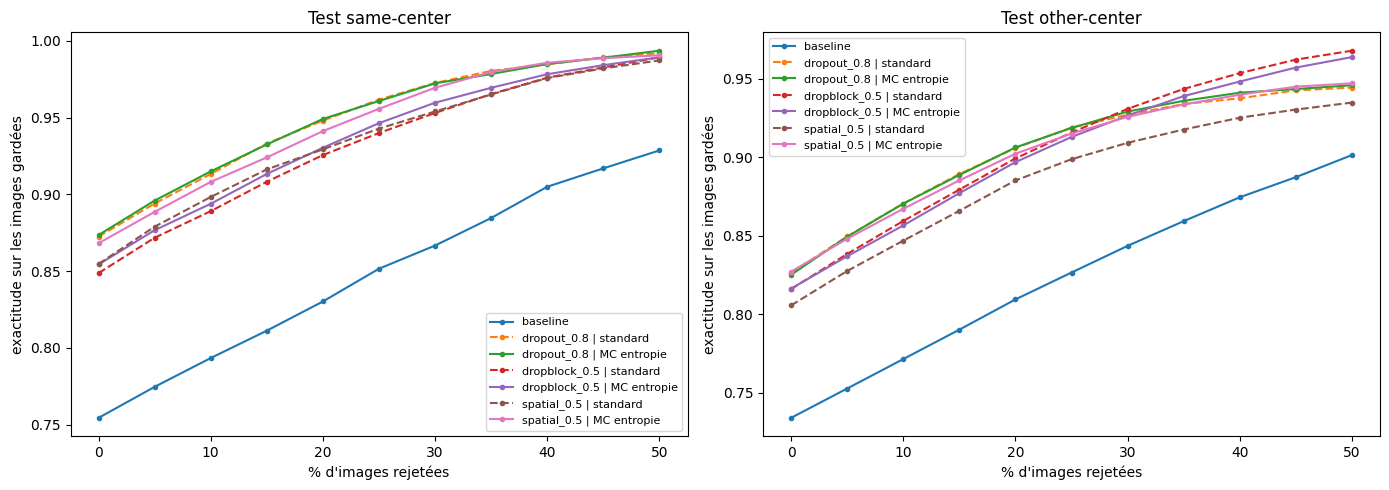

In [50]:
# ===== courbe exactitude vs taux de rejet =====
import matplotlib.pyplot as plt
def rejection_curve(y, p, score, fracs):
    """score = incertitude (plus grand = plus douteux). On retire les cas les plus douteux."""
    order = np.argsort(score)                       # du plus sûr au plus douteux
    correct = (p.argmax(1) == y)[order]
    n = len(y)
    return [correct[: n - int(f * n)].mean() for f in fracs]
fracs = np.linspace(0, 0.5, 11)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, split in zip(axes, ["same", "other"]):
    X = Xsame if split == "same" else Xother
    curves = {}
    # baseline : 1 - proba max
    curves["baseline"] = []
    for s, m in zip(TRAIN_SEEDS, ALL_MODELS["baseline"]):
        p = predict_probs(m, X)
        curves["baseline"].append(rejection_curve(MC[("dropout_0.8", s, split)]["y"], p, 1 - p.max(1), fracs))
    # les 3 méthodes : standard, MC entropie, MC info mutuelle
    for name in METHODS:
        curves[f"{name} | standard"]     = [rejection_curve(MC[(name, s, split)]["y"], MC[(name, s, split)]["p_std"], 1 - MC[(name, s, split)]["p_std"].max(1), fracs) for s in TRAIN_SEEDS]
        curves[f"{name} | MC entropie"]  = [rejection_curve(MC[(name, s, split)]["y"], MC[(name, s, split)]["p_mc"], MC[(name, s, split)]["ent"], fracs) for s in TRAIN_SEEDS]
        curves[f"{name} | MC info mut."] = [rejection_curve(MC[(name, s, split)]["y"], MC[(name, s, split)]["p_mc"], MC[(name, s, split)]["mi"], fracs) for s in TRAIN_SEEDS]
    for lab, c in curves.items():
        m = np.mean(c, 0)
        print(f"{split:5s} | {lab:30s} | 0 %: {m[0]:.4f} | 10 %: {m[2]:.4f} | 20 %: {m[4]:.4f} | gain 20 %: {m[4]-m[0]:+.4f}")
        if "info mut." not in lab:     # pas tracée (trop de courbes), mais imprimée
            ax.plot(fracs * 100, m, ls="--" if "standard" in lab else "-", marker="o", ms=3, label=lab)
    ax.set_title(f"Test {split}-center"); ax.set_xlabel("% d'images rejetées"); ax.set_ylabel("exactitude sur les images gardées")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()